# 02. Daily drift and bias against ERA5

## Purpose

Follow ERA5 + CLIM_BASE aerosol and ozone initialization (`ERA5_CLIMFILL`) and the ERA5 initialization of HYB_BASE (`ERA5_BARE`), member EN01, day by day over the 56 lead days, and verify both against ERA5. Questions: does initializing aerosols and ozone remove the cold start of the HYB_BASE member? Which radiative terms change (ozone columns, clear-sky shortwave from the aerosols, longwave from the radiative gases), and for how many days? Biases are regional means of model − ERA5 (raw values for fields without an ERA5 reference). The shading is the 10-90% range of the 20 HYB_BASE members of the same start.

**Focus: ERA5 + CLIM_BASE aerosol and ozone initialization vs the ERA5 initialization (HYB_BASE), same member.** Both runs start on 16 Dec 2011 00Z from member EN01: the same ERA5 state with the same DART perturbation EN01, over the same DATM-forced land EN01. HYB_BASE EN01 (`ERA5_BARE`) uses the ERA5 file as it is. It holds only T, U, V, Q, PS, CLDLIQ and CLDICE, and EAM starts every missing field from zero: the aerosols, ozone and the other radiative gases (`rad_climate` reads H2OLNZ, O3, N2OLNZ and CH4LNZ), and the hydrometeor numbers. `ERA5_CLIMFILL` keeps those ERA5 fields unchanged and takes every missing field from the free-running CLIM_BASE (FREE_CLIM) state of the same date (`ensemble_perturbations/util/complete_era5_ic.py`; H2OLNZ follows the ERA5 Q). The comparison `clim_fill` = ERA5_CLIMFILL − ERA5_BARE is therefore the effect of initializing aerosols, ozone and the other missing fields.

A single-member difference is judged against `ev.noise_scale`: √2 × the member spread of the 20 HYB_BASE members of the same start (`ENSEMBLE_RUN`), the chaotic divergence of two members of that ensemble. The other tests (`ERA5_DARTFILL`, `CLIMO_ATM`, `CLIMO_LND`) and production runs remain in `configs/hind_ic_test_runs.py` and can be added to `RUN_KEYS`, `PLOT_GROUPS` and `COMPARISON_KEYS`.

## Inputs and outputs

Model: `<root>/<case>_2011121600/<ENxx>/post/{atm,lnd}/180x360_aave/ts/{daily,6hourly}/0yr`, written by `post_process/regen_f20tr_ts.sh` for the production runs (`INPUT_DATA_ROOT`) and the tests (`TEST_DATA_ROOT`). Daily values per lead day, as in hind_lead_eval: 00Z-00Z means of the 6-hourly fields, and the 00Z state ending each day for the pressure levels. Reference: ERA5 1-degree (`ERA5/1x1/daily`, 00Z states from `ERA5/1x1/6hourly`); total ozone from ERA5 `TCO`.

Outputs: `data/hind_ic_test/drift/regional_<VAR>.nc` (run value and bias, ERA5, ensemble member biases, by region and lead), `comparison_windows.csv` (window means of A − B and their ratio to the noise scale), `ensemble_<RUN>_<VAR>.nc` (member biases of a second ensemble) and `ensemble_comparison_windows.csv` (a test member against that ensemble); figures `figure/hind_ic_test/drift/drift_<GROUP>_<REGION>.png` and `ensemble_<COMPARISON>_<REGION>.png`.

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

## 2. User setup

Plain values only, so `papermill -p` overrides work.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")            # production F20TR hindcasts
TEST_DATA_ROOT = Path("/pscratch/sd/z/zhan391/e3sm_dart/simulation")             # the test runs
IC_ROOT = Path("/global/cfs/cdirs/m4849/zhan391")                                  # initial-file library (DART_INIT/, e3sm_dart/)
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")                     # reference-data archive
LAND_SUPPORT_DIR = OBSERVATION_ROOT / "lnd_sea_mask"
WORKFLOW_NAME = "hind_ic_test"

RUN_KEYS = ("ERA5_BARE", "ERA5_CLIMFILL")          # HYB_BASE EN01 and ERA5 + CLIM_BASE fill EN01 (configs/hind_ic_test_runs.py)
ENSEMBLE_RUN = "ERA5_BARE"         # its whole ensemble (HYB_BASE, 20 members) gives the shading and the noise scale
MAX_MEMBERS = None                 # e.g. 5 for a quick look
MAX_LEAD = 56
VARIABLES = ("TREFHT", "TS", "T850", "T100", "T050", "T010", "Z500", "TOZ", "SCO", "TCO",
             "FSDSC", "FSNTOAC", "FSDS", "FLDS", "FLDSC", "FLUTC", "FLUT", "LHFLX", "SHFLX", "TMQ", "PRECT", "CLDTOT", "PSL")
REGIONS = ("GLOBAL", "LAND", "OCEAN", "NH_LAND", "TROPICS", "NH_POLAR", "SH_POLAR")
WINDOWS = {"days 1-3": (1, 3), "days 4-10": (4, 10), "days 11-28": (11, 28), "days 29-56": (29, 56)}
# Second comparison: a test member against the whole ensemble of another configuration
# (configs/hind_ic_test_runs.py ENSEMBLE_COMPARISONS); the run must be in RUN_KEYS
ENSEMBLE_COMPARISON_KEYS = ("climfill_vs_dacoupled",)
ENSEMBLE_COMPARISON_VARIABLES = ("TREFHT", "TS", "T850", "T100", "T050", "T010", "Z500", "TOZ", "SCO", "TCO",
                                 "FSDSC", "FLDS", "FLDSC", "LHFLX", "PRECT")
TOPIC = "drift"
FORCE_COMPUTE = False

# plotting
PLOT_GROUPS = ("era5_clim_fill",)
PLOT_REGIONS = ("LAND", "NH_LAND", "OCEAN", "GLOBAL")
PLOT_ENSEMBLE_VARIABLES = ("TREFHT", "T850", "Z500", "T100", "T050", "T010", "TOZ", "SCO", "FLDS", "PRECT")
PLOT_VARIABLES = ("TREFHT", "T850", "T050", "T010", "TOZ", "SCO", "TCO", "FSDSC", "FSNTOAC", "FLDS", "FLDSC", "PRECT")
FIGURE_DPI = 200
SHOW = True

## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from util import hind_ic_test_eval as ev
from configs.hind_ic_test_runs import COMPARISONS, ENSEMBLE_COMPARISONS, GROUPS, INIT, RUNS, check_runs, ensemble_members, member_dir
from util.hind_case_io import cached_dataset, cached_table, figure_saver

check_runs(RUN_KEYS)
ROOTS = {"test": TEST_DATA_ROOT, "production": INPUT_DATA_ROOT}
data_dir = DIAGNOSTIC_OUTPUT_ROOT / "data" / WORKFLOW_NAME / TOPIC
figure_dir = DIAGNOSTIC_OUTPUT_ROOT / "figure" / WORKFLOW_NAME / TOPIC
data_dir.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)
save = figure_saver(figure_dir, dpi=FIGURE_DPI, show=SHOW)
print(f"[DATA] {data_dir}\n[FIGURE] {figure_dir}")

runs = pd.DataFrame([dict(run=k, case=f"{r.case}_{INIT.astype(object):%Y%m%d}00", member=r.member, source=r.source,
                          atmosphere=r.atm_ic, land=r.lnd_ic) for k, r in RUNS.items() if k in RUN_KEYS]).set_index("run")
display(runs)
display(pd.DataFrame([dict(comparison=k, A=a, B=b, question=q) for k, (a, b, q) in COMPARISONS.items()]).set_index("comparison"))

ens_case = RUNS[ENSEMBLE_RUN].case
ens_members = ensemble_members(ens_case, INIT, ROOTS[RUNS[ENSEMBLE_RUN].source])[:MAX_MEMBERS]
print(f"[ENSEMBLE] {ENSEMBLE_RUN}: {len(ens_members)} members")
streams = {"atm_daily", "atm_6hourly"} | ({"lnd_daily"} if any(ev.spec(v).component == "lnd" for v in VARIABLES) else set())
paths = {k: member_dir(k, ROOTS) for k in RUN_KEYS}
not_ready = [f"{k}:{s}" for k, p in paths.items() for s in streams if not ev.stream_ok(p, s)]
not_ready += [f"{ENSEMBLE_RUN} {m}:{s}" for m in ens_members for s in streams
              if not ev.stream_ok(member_dir(ENSEMBLE_RUN, ROOTS).parent / m, s)]
unknown = [c for c in ENSEMBLE_COMPARISON_KEYS if c not in ENSEMBLE_COMPARISONS
           or ENSEMBLE_COMPARISONS[c][0] not in RUN_KEYS]
if unknown:
    raise KeyError(f"ensemble comparisons {unknown} unknown or their run not in RUN_KEYS; choose from {list(ENSEMBLE_COMPARISONS)}")
other_ensembles = {}
for c in ENSEMBLE_COMPARISON_KEYS:
    e = ENSEMBLE_COMPARISONS[c][1]
    other_ensembles[e] = ensemble_members(RUNS[e].case, INIT, ROOTS[RUNS[e].source])[:MAX_MEMBERS]
    print(f"[ENSEMBLE] {e}: {len(other_ensembles[e])} members (ensemble comparison {c})")
    not_ready += [f"{e} {m}:{s}" for m in other_ensembles[e] for s in streams
                  if not ev.stream_ok(member_dir(e, ROOTS).parent / m, s)]
if not_ready:
    raise RuntimeError(f"time series not regenerated (run post_process/regen_f20tr_ts.sh): {not_ready}")

[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/drift
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_ic_test/drift


,case,member,source,atmosphere,land
run,,,,,
ERA5_BARE,F20TR_ne30pg2_r05_IcoswISC30E3r5_HYB_BASE_2011...,EN01,production,"bare ERA5 (T, U, V, Q, PS, CLDLIQ, CLDICE only)",DATM EN01
ERA5_CLIMFILL,F20TR_ne30pg2_r05_IcoswISC30E3r5_ERA5CLIMFILL_...,EN01,test,ERA5 + CLIM_BASE fields,DATM EN01


,A,B,question
comparison,,,
clim_fill,ERA5_CLIMFILL,ERA5_BARE,ERA5 + CLIM_BASE aerosol and ozone initializat...
tracer_fix,ERA5_DARTFILL,ERA5_BARE,Does completing the ERA5 state remove the cold...
fill_source,ERA5_CLIMFILL,ERA5_DARTFILL,Does the source of the filled fields matter? (...
atm_clim,CLIMO_ATM,DA_COUPLED,"Atmosphere initial state, complete states: CLI..."
atm_bare_era5,DA_LND,DA_COUPLED,Atmosphere initial state as run in production ...
lnd_clim,CLIMO_LND,DA_COUPLED,Land initial state: CLIM_BASE - DART (both und...
lnd_datm,DA_ATM,DA_COUPLED,Land initial state as run in production DA_ATM...


[ENSEMBLE] ERA5_BARE: 20 members
[ENSEMBLE] DA_COUPLED: 20 members (ensemble comparison climfill_vs_dacoupled)


## 4. Regional daily series

One file per variable: each run's regional mean and its bias against ERA5, ERA5 itself, and the bias of every member of the ensemble run. The file is reused while the runs, members, regions and lead range are unchanged.

In [4]:
grid_ref = ev.open_member(paths[RUN_KEYS[0]], INIT, "TREFHT", MAX_LEAD)
masks = ev.region_masks(REGIONS, grid_ref.lat, grid_ref.lon, LAND_SUPPORT_DIR).load()
stamp = "|".join([",".join(f"{k}={paths[k]}" for k in RUN_KEYS), ",".join(ens_members), ",".join(REGIONS), str(MAX_LEAD)])


def build_regional(v):
    ref = ev.open_era5(v, INIT, MAX_LEAD, OBSERVATION_ROOT)
    ref_r = None if ref is None else ev.regional_mean(ref, masks).load()
    def series(p):
        f = ev.open_member(p, INIT, v, MAX_LEAD)
        val = ev.regional_mean(f, masks).load()
        return val, (None if ref is None else ev.regional_mean(f - ref, masks).load())
    vals, biases = zip(*(series(paths[k]) for k in RUN_KEYS))
    ens = [series(member_dir(ENSEMBLE_RUN, ROOTS).parent / m) for m in ens_members]
    ds = xr.Dataset({"value": xr.concat(vals, pd.Index(list(RUN_KEYS), name="run")),
                     "ens_value": xr.concat([e[0] for e in ens], pd.Index(ens_members, name="member"))})
    if ref is not None:
        ds["bias"] = xr.concat(biases, pd.Index(list(RUN_KEYS), name="run"))
        ds["ens_bias"] = xr.concat([e[1] for e in ens], pd.Index(ens_members, name="member"))
        ds["era5"] = ref_r
    ds.attrs.update(variable=v, units=ev.spec(v).units, long_name=ev.spec(v).long_name, ensemble_run=ENSEMBLE_RUN,
                    reference="ERA5 " + ev.spec(v).era5 if ref is not None else "none")
    return ds.drop_vars([c for c in ("date",) if c in ds.coords])


regional = {}
for v in VARIABLES:
    regional[v] = cached_dataset(data_dir / f"regional_{v}.nc", lambda v=v: build_regional(v), stamp, force=FORCE_COMPUTE)

[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/drift/regional_TREFHT.nc
[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/drift/regional_TS.nc
[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/drift/regional_T850.nc
[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/drift/regional_T100.nc
[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/drift/regional_T050.nc
[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/drift/regional_T010.nc
[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/drift/regional_Z500.nc
[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/drift/regional_TOZ.nc
[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/drift/regional_SCO.nc
[READ] /global/cfs/cdirs/e3sm/

## 5. Comparisons by lead window

For each comparison A − B (`COMPARISONS`): the window mean of the regional difference, and its ratio to the noise scale (√2 × the ensemble spread of the regional mean in that window). |ratio| > 2 marks a difference unlikely to come from member-to-member chaos alone (in days 1-3 the ensemble spread is still set by the initial perturbations, so the ratio is large for any IC difference).

In [5]:
def comparison_table():
    rows = []
    for v, ds in regional.items():
        val = ds["value"]
        noise = ev.window_means(ev.noise_scale(ds["ens_value"]), WINDOWS)
        for c, (a, b, _) in COMPARISONS.items():
            if a not in val.run or b not in val.run:
                continue
            d = ev.window_means(val.sel(run=a) - val.sel(run=b), WINDOWS)
            for r in ds.region.values:
                for w in WINDOWS:
                    x, n = float(d.sel(region=r, window=w)), float(noise.sel(region=r, window=w))
                    rows.append(dict(comparison=c, variable=v, units=ds.attrs["units"], region=r, window=w,
                                     difference=x, noise=n, ratio=x / n if n > 0 else np.nan))
    return pd.DataFrame(rows)


table = comparison_table()
table.to_csv(data_dir / "comparison_windows.csv", index=False)
print(f"[WRITE] {data_dir / 'comparison_windows.csv'}")
for region in ("LAND", "GLOBAL"):
    for var in ("TREFHT", "T850", "TOZ", "SCO", "FSDSC", "FSNTOAC", "FLDS"):
        sel = table[(table.region == region) & (table.variable == var)]
        if len(sel):
            t = sel.pivot(index="comparison", columns="window", values="difference")[list(WINDOWS)]
            r = sel.pivot(index="comparison", columns="window", values="ratio")[list(WINDOWS)]
            print(f"\n{var} ({sel.units.iloc[0]}), {region}: A - B (ratio to noise)")
            display(t.round(2).astype(str) + " (" + r.round(1).astype(str) + ")")

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/drift/comparison_windows.csv

TREFHT (K), LAND: A - B (ratio to noise)


window,days 1-3,days 4-10,days 11-28,days 29-56
comparison,,,,
clim_fill,6.06 (52.0),6.12 (24.5),5.22 (8.5),-0.6 (-0.8)



T850 (K), LAND: A - B (ratio to noise)


window,days 1-3,days 4-10,days 11-28,days 29-56
comparison,,,,
clim_fill,1.86 (20.8),4.1 (19.6),3.34 (7.4),-1.06 (-1.6)



TOZ (DU), LAND: A - B (ratio to noise)


window,days 1-3,days 4-10,days 11-28,days 29-56
comparison,,,,
clim_fill,241.17 (2449.3),205.22 (673.9),168.71 (131.0),137.18 (61.4)


... (18 outputs left out)


FSNTOAC (W m-2), GLOBAL: A - B (ratio to noise)


window,days 1-3,days 4-10,days 11-28,days 29-56
comparison,,,,
clim_fill,7.51 (185.1),6.27 (91.2),4.15 (24.3),0.58 (1.7)



FLDS (W m-2), GLOBAL: A - B (ratio to noise)


window,days 1-3,days 4-10,days 11-28,days 29-56
comparison,,,,
clim_fill,95.83 (42.0),72.22 (46.8),58.82 (23.6),17.87 (10.4)


## 6. Figures: bias by lead day

One figure per run group and region, one panel per variable. Lines show each run's bias against ERA5 (or its raw value when there is no reference). Shading is the 10-90% range of the ensemble members, and the thin black line is the ensemble median.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_ic_test/drift/drift_era5_clim_fill_LAND.png


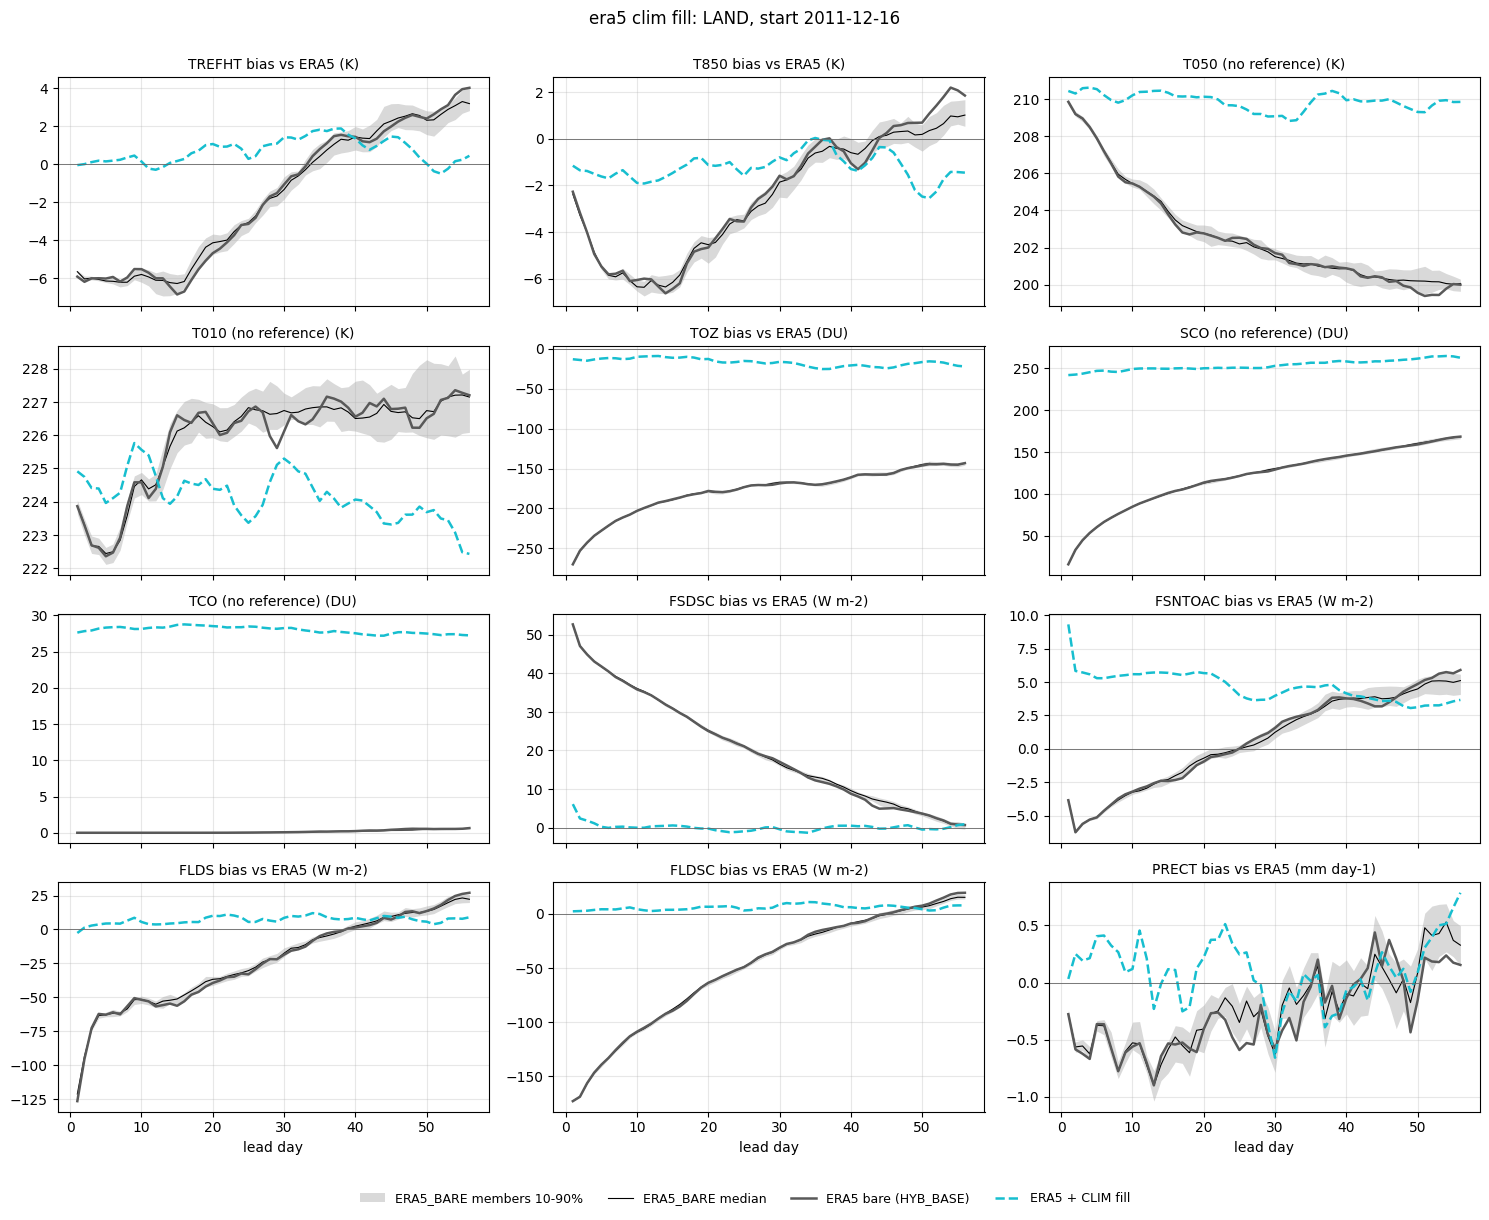

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_ic_test/drift/drift_era5_clim_fill_NH_LAND.png


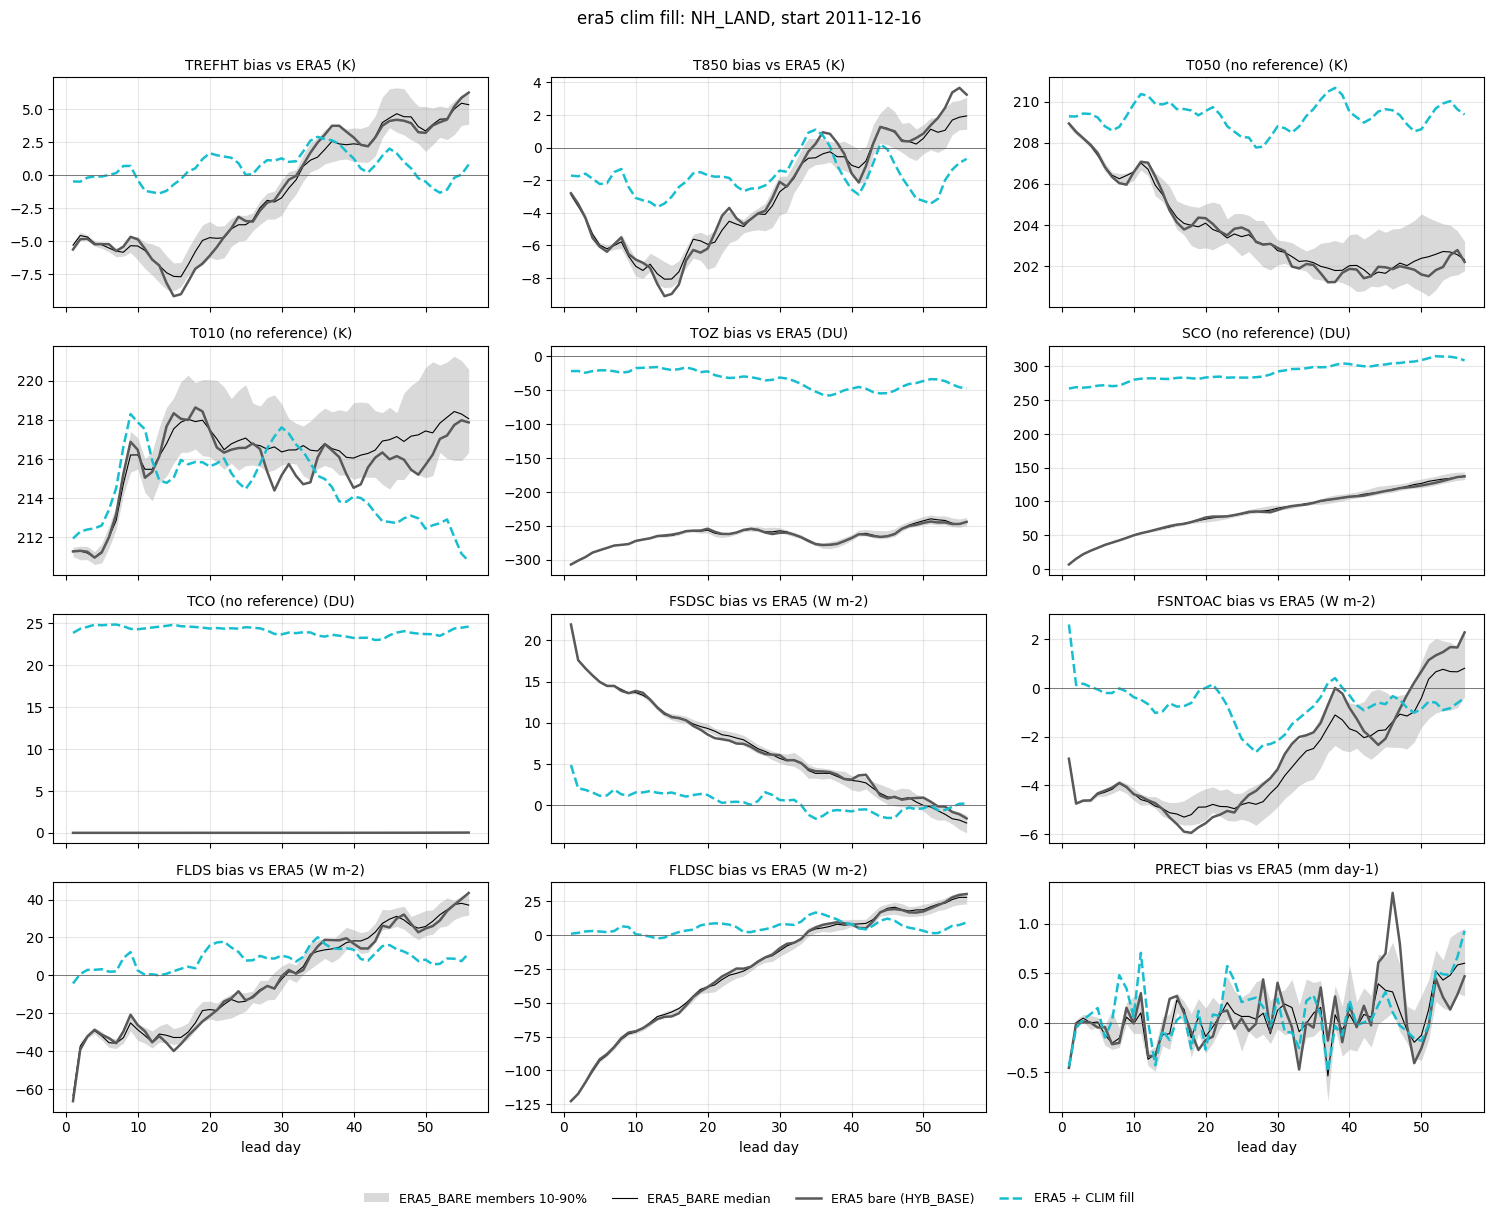

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_ic_test/drift/drift_era5_clim_fill_OCEAN.png


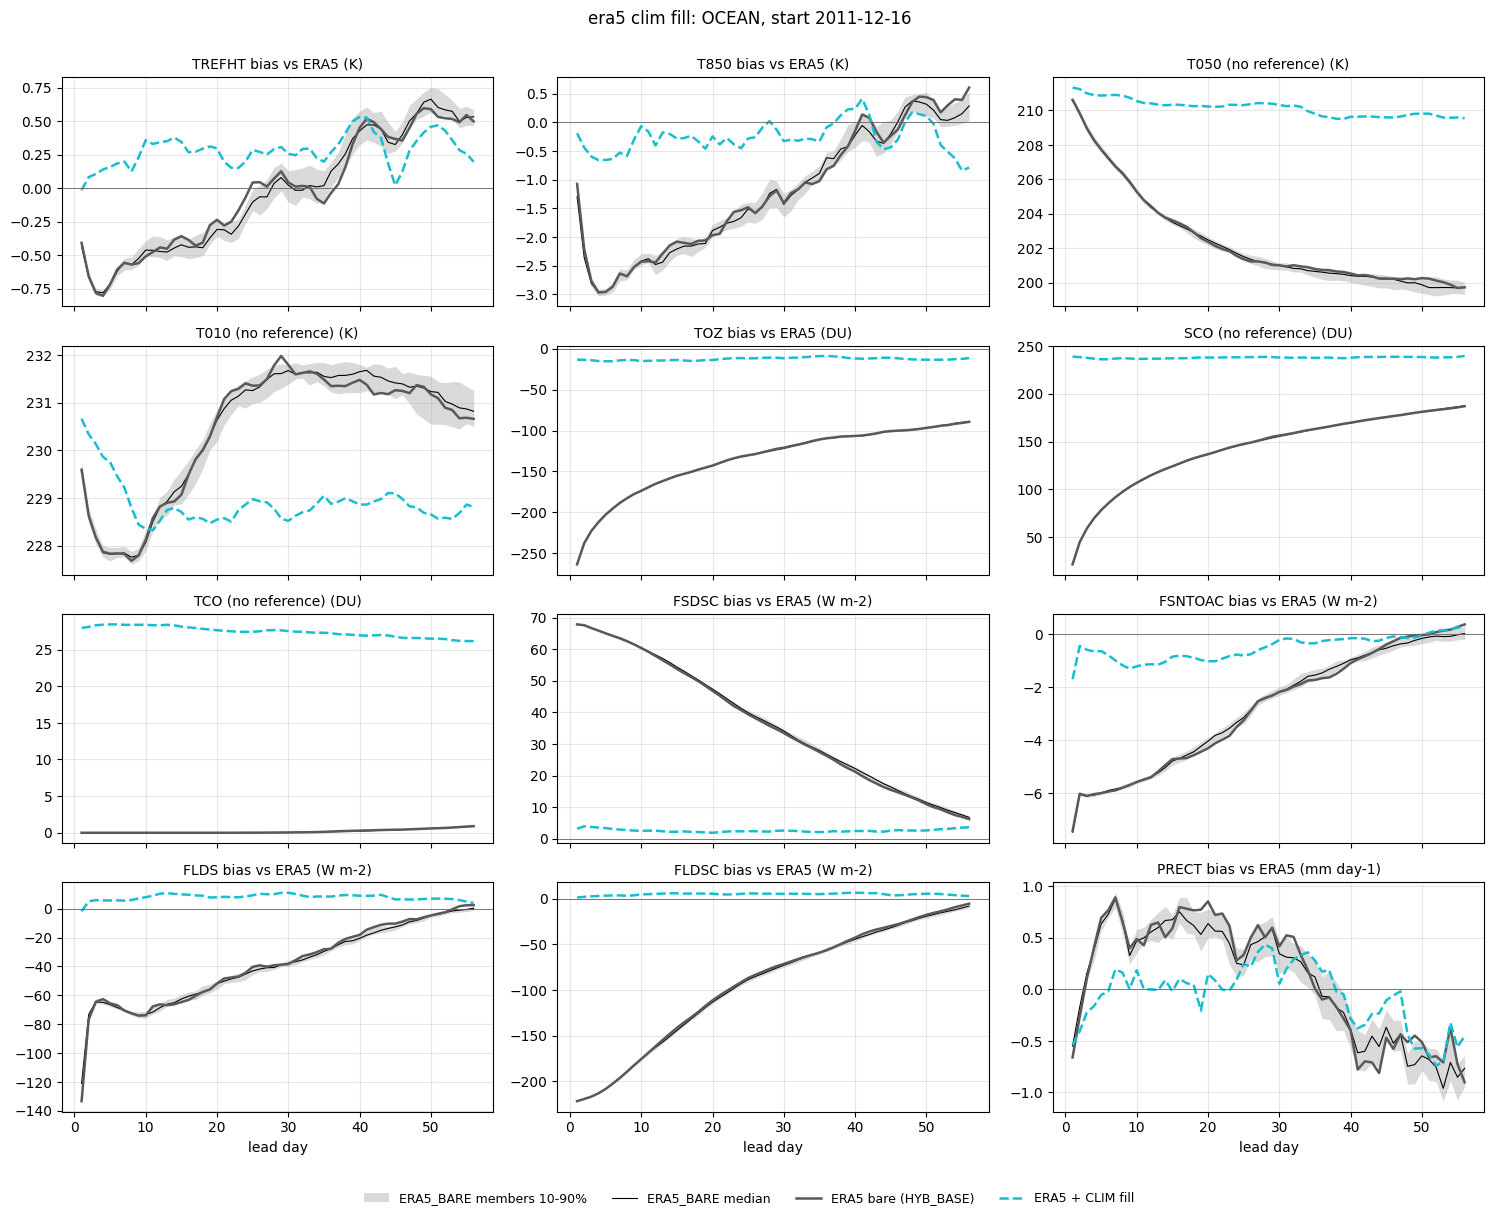

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_ic_test/drift/drift_era5_clim_fill_GLOBAL.png


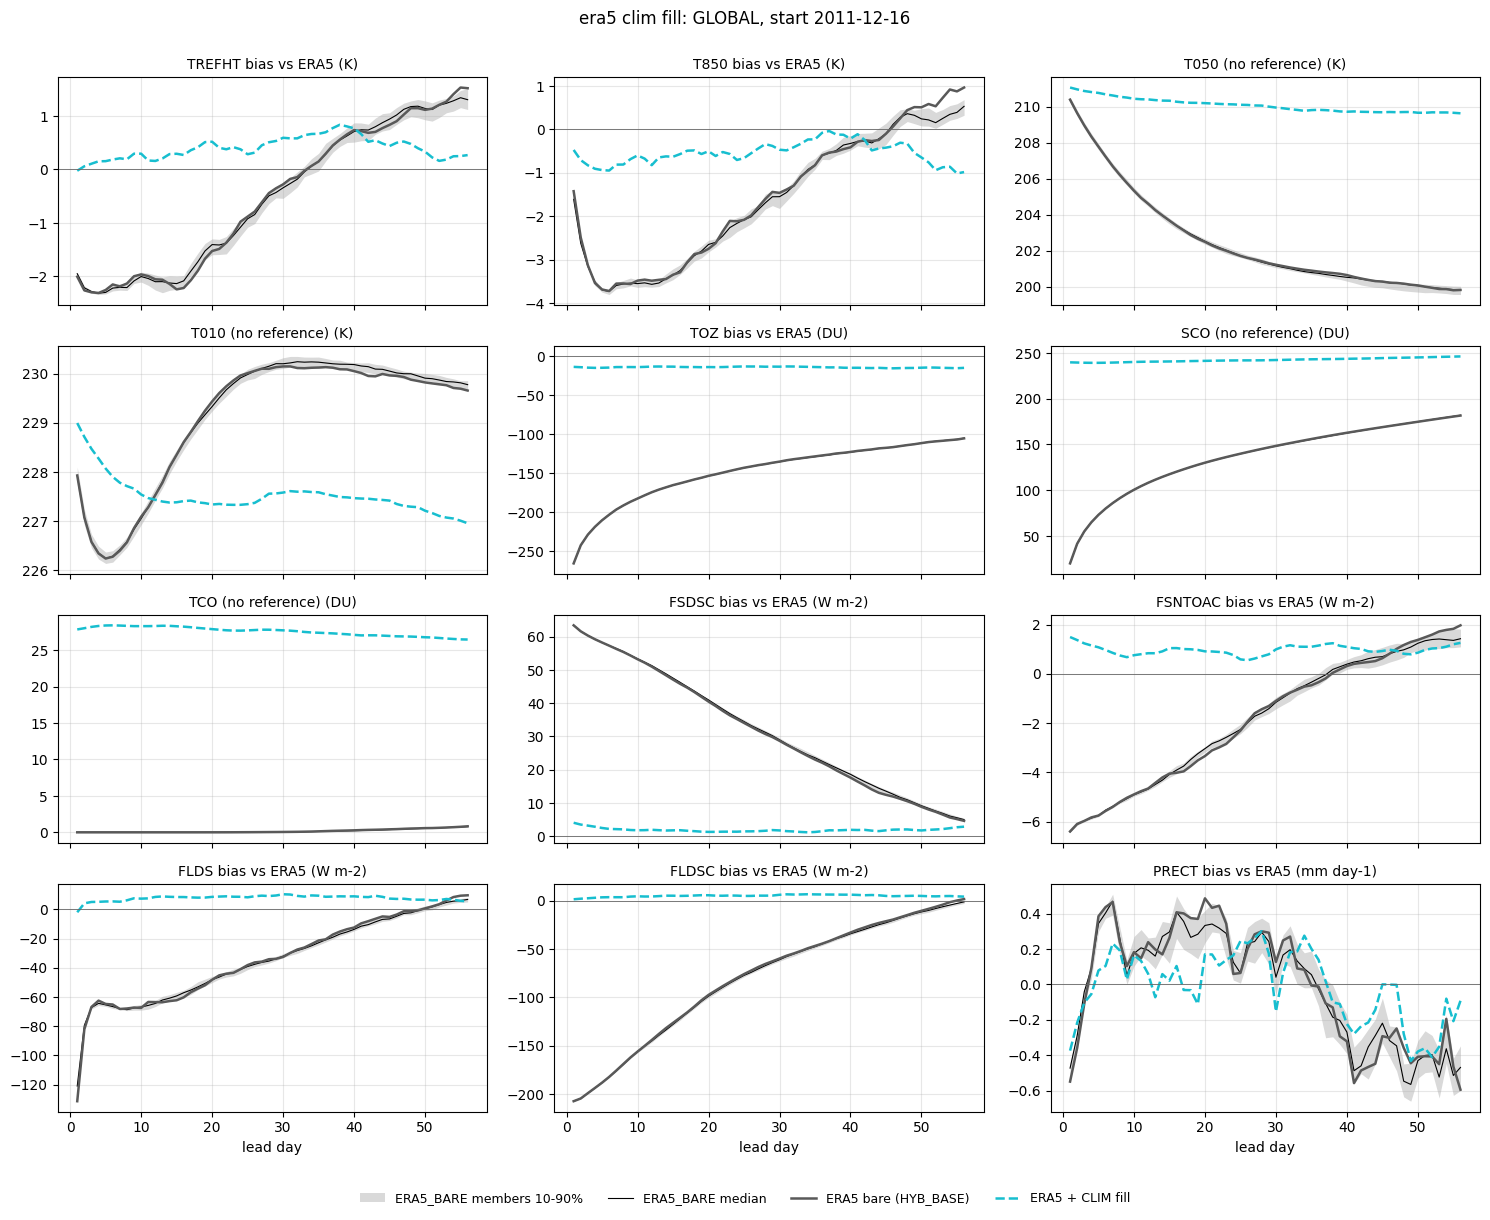

In [6]:
def plot_group(group, region):
    keys = [k for k in GROUPS[group] if k in RUN_KEYS]
    vs = [v for v in PLOT_VARIABLES if v in regional]
    ncol = 3
    nrow = int(np.ceil(len(vs) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(5.0 * ncol, 2.9 * nrow), sharex=True, squeeze=False)
    for ax, v in zip(axes.flat, vs):
        ds = regional[v]
        has_ref = "bias" in ds
        y, ens = (ds["bias"], ds["ens_bias"]) if has_ref else (ds["value"], ds["ens_value"])
        e = ens.sel(region=region)
        ax.fill_between(e.lead, e.quantile(0.1, "member"), e.quantile(0.9, "member"), color="0.85", lw=0,
                        label=f"{ENSEMBLE_RUN} members 10-90%")
        ax.plot(e.lead, e.median("member"), color="k", lw=0.8, label=f"{ENSEMBLE_RUN} median")
        for k in keys:
            r = RUNS[k]
            ax.plot(y.lead, y.sel(run=k, region=region), color=r.color, ls=r.linestyle, lw=1.8, label=r.label)
        if has_ref:
            ax.axhline(0, color="0.4", lw=0.6)
        ax.set_title(f"{v} {'bias vs ERA5' if has_ref else '(no reference)'} ({ds.attrs['units']})", fontsize=10)
        ax.grid(alpha=0.3)
    for ax in axes[-1]:
        ax.set_xlabel("lead day")
    for ax in list(axes.flat)[len(vs):]:
        ax.axis("off")
    h, l = axes.flat[0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=4, fontsize=9, frameon=False, bbox_to_anchor=(0.5, -0.04))
    fig.suptitle(f"{group.replace('_', ' ')}: {region}, start {INIT}", y=1.0)
    fig.tight_layout()
    save(fig, f"drift_{group}_{region}.png")
    plt.show()


for g in PLOT_GROUPS:
    for r in PLOT_REGIONS:
        plot_group(g, r)

## 7. Second comparison: a test member against another configuration's ensemble

`ENSEMBLE_COMPARISONS` (`configs/hind_ic_test_runs.py`): by default ERA5 + CLIM_BASE fill (`ERA5_CLIMFILL` EN01, DATM land) against the 20 DA_COUPLED members of the same start (DART atmosphere and land). Both atmosphere and land initial states differ, so this asks whether the completed ERA5 hindcast behaves like a DA_COUPLED member, not which component causes a difference. Both are verified against ERA5. Per region and lead window: the run's bias, the ensemble-mean bias, their difference, `z` = difference / (spread × √(1 + 1/N)), and `rank`, the number of members below the run (0 or N = outside every member; probability 1/(N+1) on each side by chance). In days 1-3 the DART perturbations are still small, so `z` is large for any initial-state difference.

In [7]:
def build_ensemble(run, v):
    """Regional bias against ERA5 (or value) of every member of ``run``'s case."""
    ref = ev.open_era5(v, INIT, MAX_LEAD, OBSERVATION_ROOT)
    members = other_ensembles[run]
    out = []
    for m in members:
        f = ev.open_member(member_dir(run, ROOTS).parent / m, INIT, v, MAX_LEAD)
        out.append(ev.regional_mean(f if ref is None else f - ref, masks).load())
    da = xr.concat(out, pd.Index(members, name="member")).rename("ens_bias" if ref is not None else "ens_value")
    ds = da.to_dataset()
    ds.attrs.update(variable=v, units=ev.spec(v).units, long_name=ev.spec(v).long_name, ensemble_run=run,
                    reference="ERA5 " + ev.spec(v).era5 if ref is not None else "none")
    return ds.drop_vars([c for c in ("date",) if c in ds.coords])


ensembles = {}
for run, members in other_ensembles.items():
    st = "|".join([run, ",".join(members), ",".join(REGIONS), str(MAX_LEAD)])
    for v in ENSEMBLE_COMPARISON_VARIABLES:
        if v in regional:
            ensembles[run, v] = cached_dataset(data_dir / f"ensemble_{run}_{v}.nc", lambda r=run, v=v: build_ensemble(r, v),
                                               st, force=FORCE_COMPUTE)

rows = []
for c in ENSEMBLE_COMPARISON_KEYS:
    run, ens_run, _ = ENSEMBLE_COMPARISONS[c]
    for v in ENSEMBLE_COMPARISON_VARIABLES:
        if (ens_run, v) not in ensembles:
            continue
        ds, e = regional[v], ensembles[ens_run, v]
        key = "bias" if "bias" in ds else "value"
        t = ev.member_vs_ensemble(ds[key].sel(run=run), e[f"ens_{key}"], WINDOWS)
        rows.append(t.assign(comparison=c, variable=v, units=ds.attrs["units"], quantity=key))
ens_table = pd.concat(rows, ignore_index=True)
ens_table.to_csv(data_dir / "ensemble_comparison_windows.csv", index=False)
print(f"[WRITE] {data_dir / 'ensemble_comparison_windows.csv'}")
for c in ENSEMBLE_COMPARISON_KEYS:
    run, ens_run, q = ENSEMBLE_COMPARISONS[c]
    print(f"\n{c}: {q}")
    for region in ("GLOBAL", "LAND"):
        sel = ens_table[(ens_table.comparison == c) & (ens_table.region == region)]
        t = sel.assign(cell=sel.apply(lambda x: f"{x.run:+.2f} / {x.ensemble_mean:+.2f} [z {x.z:+.1f}, rank {x['rank']}]", axis=1))
        print(f"\n{region}: {run} / {ens_run} mean {sel.quantity.iloc[0]} [z, rank of {sel.members.iloc[0]}]")
        display(t.pivot(index="variable", columns="window", values="cell")[list(WINDOWS)]
                .loc[[v for v in ENSEMBLE_COMPARISON_VARIABLES if v in set(sel.variable)]])

[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/drift/ensemble_DA_COUPLED_TREFHT.nc
[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/drift/ensemble_DA_COUPLED_TS.nc
[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/drift/ensemble_DA_COUPLED_T850.nc
[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/drift/ensemble_DA_COUPLED_T100.nc
[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/drift/ensemble_DA_COUPLED_T050.nc
[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/drift/ensemble_DA_COUPLED_T010.nc
[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/drift/ensemble_DA_COUPLED_Z500.nc
[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/drift/ensemble_DA_COUPLED_TOZ.nc
[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_da

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/drift/ensemble_comparison_windows.csv

climfill_vs_dacoupled: ERA5 + CLIM_BASE fill (DATM land) against the DA_COUPLED ensemble (DART atmosphere and land)

GLOBAL: ERA5_CLIMFILL / DA_COUPLED mean bias [z, rank of 20]


window,days 1-3,days 4-10,days 11-28,days 29-56
variable,,,,
TREFHT,"+0.05 / +0.11 [z -4.8, rank 0]","+0.21 / +0.24 [z -1.0, rank 3]","+0.35 / +0.33 [z +0.3, rank 13]","+0.51 / +0.57 [z -0.4, rank 7]"
TS,"+0.42 / +0.50 [z -6.7, rank 0]","+0.53 / +0.58 [z -1.5, rank 0]","+0.60 / +0.59 [z +0.1, rank 13]","+0.77 / +0.81 [z -0.3, rank 7]"
T850,"-0.67 / -0.82 [z +5.0, rank 20]","-0.81 / -0.84 [z +0.8, rank 17]","-0.58 / -0.62 [z +0.4, rank 14]","-0.44 / -0.42 [z -0.2, rank 8]"
T100,"+0.39 / -0.49 [z +5.2, rank 20]","+0.06 / -0.73 [z +5.2, rank 20]","-0.47 / -0.81 [z +2.2, rank 20]","-0.86 / -1.26 [z +2.2, rank 20]"
T050,"+210.97 / +210.74 [z +1.8, rank 19]","+210.63 / +210.20 [z +3.1, rank 20]","+210.22 / +209.35 [z +5.8, rank 20]","+209.75 / +208.58 [z +5.9, rank 20]"
T010,"+228.73 / +228.05 [z +4.5, rank 20]","+227.85 / +227.38 [z +4.5, rank 20]","+227.39 / +227.22 [z +2.3, rank 20]","+227.38 / +227.18 [z +2.4, rank 20]"
Z500,"+3.36 / -13.64 [z +2.9, rank 19]","+5.95 / -10.02 [z +2.9, rank 19]","+10.61 / -6.78 [z +2.9, rank 19]","+10.48 / -3.30 [z +2.3, rank 19]"
TOZ,"-13.86 / -5.32 [z -95.3, rank 0]","-14.01 / -5.37 [z -122.4, rank 0]","-13.29 / -4.43 [z -67.6, rank 0]","-14.24 / -4.72 [z -19.9, rank 0]"
SCO,"+239.48 / +252.68 [z -148.4, rank 0]","+239.52 / +252.75 [z -238.1, rank 0]","+241.21 / +253.38 [z -79.6, rank 0]","+244.03 / +254.94 [z -22.8, rank 0]"



LAND: ERA5_CLIMFILL / DA_COUPLED mean bias [z, rank of 20]


window,days 1-3,days 4-10,days 11-28,days 29-56
variable,,,,
TREFHT,"+0.02 / +0.28 [z -7.0, rank 0]","+0.24 / +0.41 [z -1.3, rank 1]","+0.54 / +0.34 [z +0.6, rank 15]","+0.98 / +1.28 [z -0.6, rank 5]"
TS,"+0.63 / +0.91 [z -7.2, rank 0]","+0.86 / +1.00 [z -1.1, rank 1]","+1.08 / +0.88 [z +0.7, rank 16]","+1.55 / +1.82 [z -0.5, rank 5]"
T850,"-1.30 / -1.24 [z -1.5, rank 1]","-1.60 / -1.44 [z -1.4, rank 0]","-1.32 / -1.51 [z +0.8, rank 16]","-1.06 / -0.85 [z -0.7, rank 3]"
T100,"+0.29 / -0.49 [z +4.7, rank 20]","+0.48 / -0.32 [z +4.0, rank 20]","-0.39 / -0.50 [z +0.4, rank 14]","-0.84 / -1.48 [z +2.3, rank 20]"
T050,"+210.43 / +210.33 [z +0.7, rank 17]","+210.17 / +209.65 [z +2.8, rank 19]","+209.97 / +209.34 [z +3.3, rank 20]","+209.69 / +208.75 [z +2.9, rank 20]"
T010,"+224.69 / +224.33 [z +2.1, rank 19]","+224.73 / +224.39 [z +1.6, rank 20]","+224.27 / +224.91 [z -1.3, rank 0]","+223.90 / +224.38 [z -0.8, rank 4]"
Z500,"+5.74 / -11.60 [z +2.8, rank 19]","+4.12 / -8.82 [z +2.1, rank 19]","+15.36 / -4.18 [z +3.0, rank 20]","+7.03 / +5.24 [z +0.2, rank 13]"
TOZ,"-14.07 / +1.60 [z -55.1, rank 0]","-12.13 / +1.14 [z -31.0, rank 0]","-13.42 / +0.35 [z -17.7, rank 0]","-20.55 / -7.75 [z -6.3, rank 0]"
SCO,"+242.47 / +262.16 [z -69.1, rank 0]","+246.60 / +263.81 [z -37.6, rank 0]","+249.87 / +266.96 [z -20.5, rank 0]","+258.36 / +272.42 [z -6.8, rank 0]"


One figure per ensemble comparison and region: the other ensemble's 10-90% range and median, the test member, and the runs of `RUN_KEYS` for reference.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_ic_test/drift/ensemble_climfill_vs_dacoupled_LAND.png


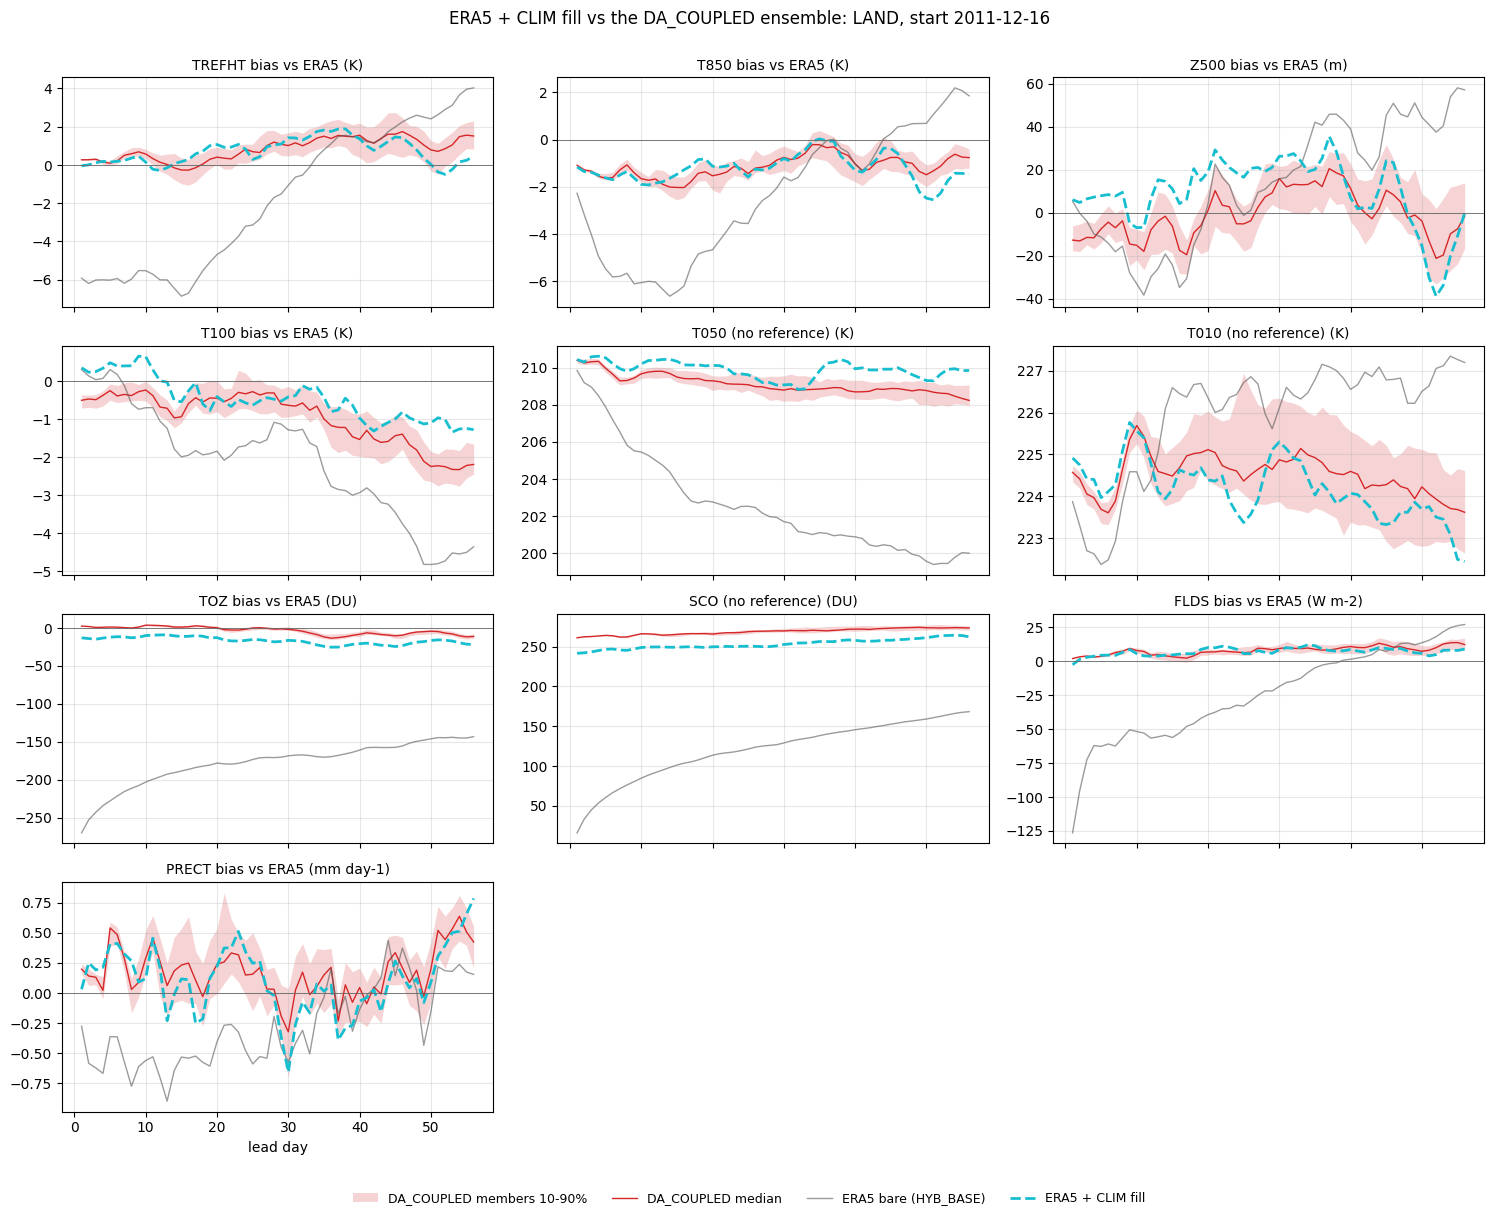

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_ic_test/drift/ensemble_climfill_vs_dacoupled_NH_LAND.png


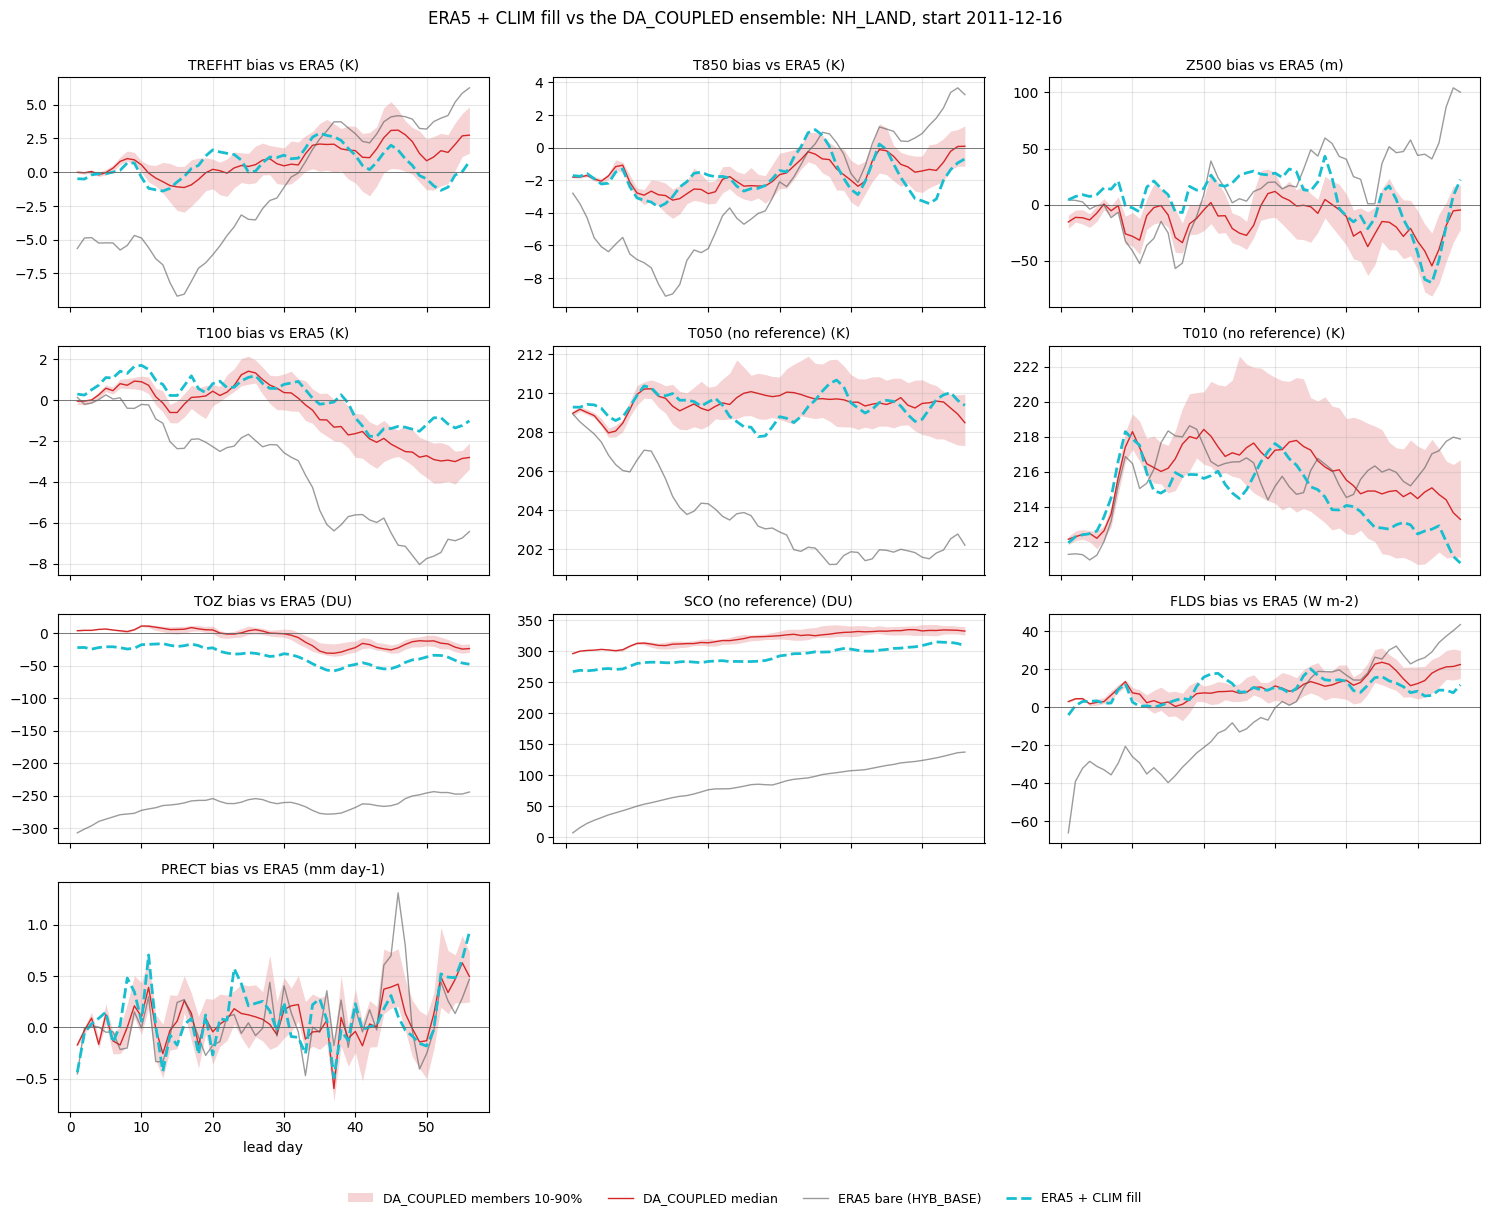

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_ic_test/drift/ensemble_climfill_vs_dacoupled_OCEAN.png


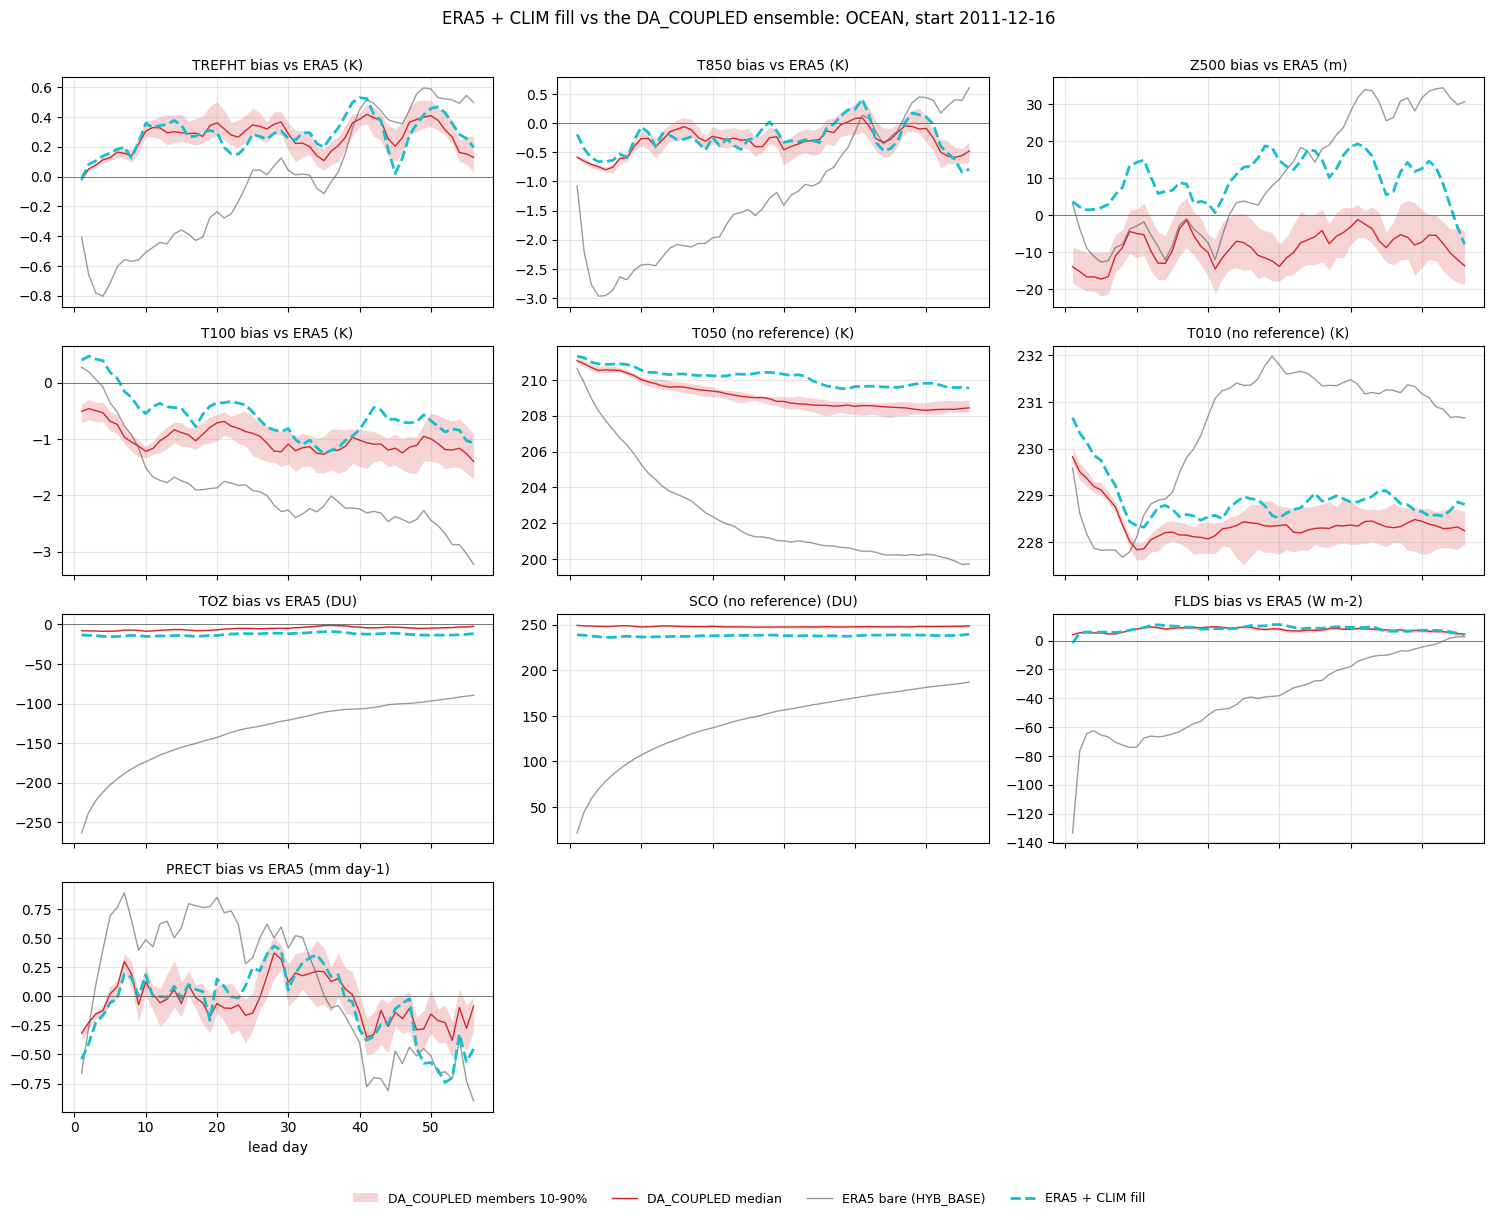

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_ic_test/drift/ensemble_climfill_vs_dacoupled_GLOBAL.png


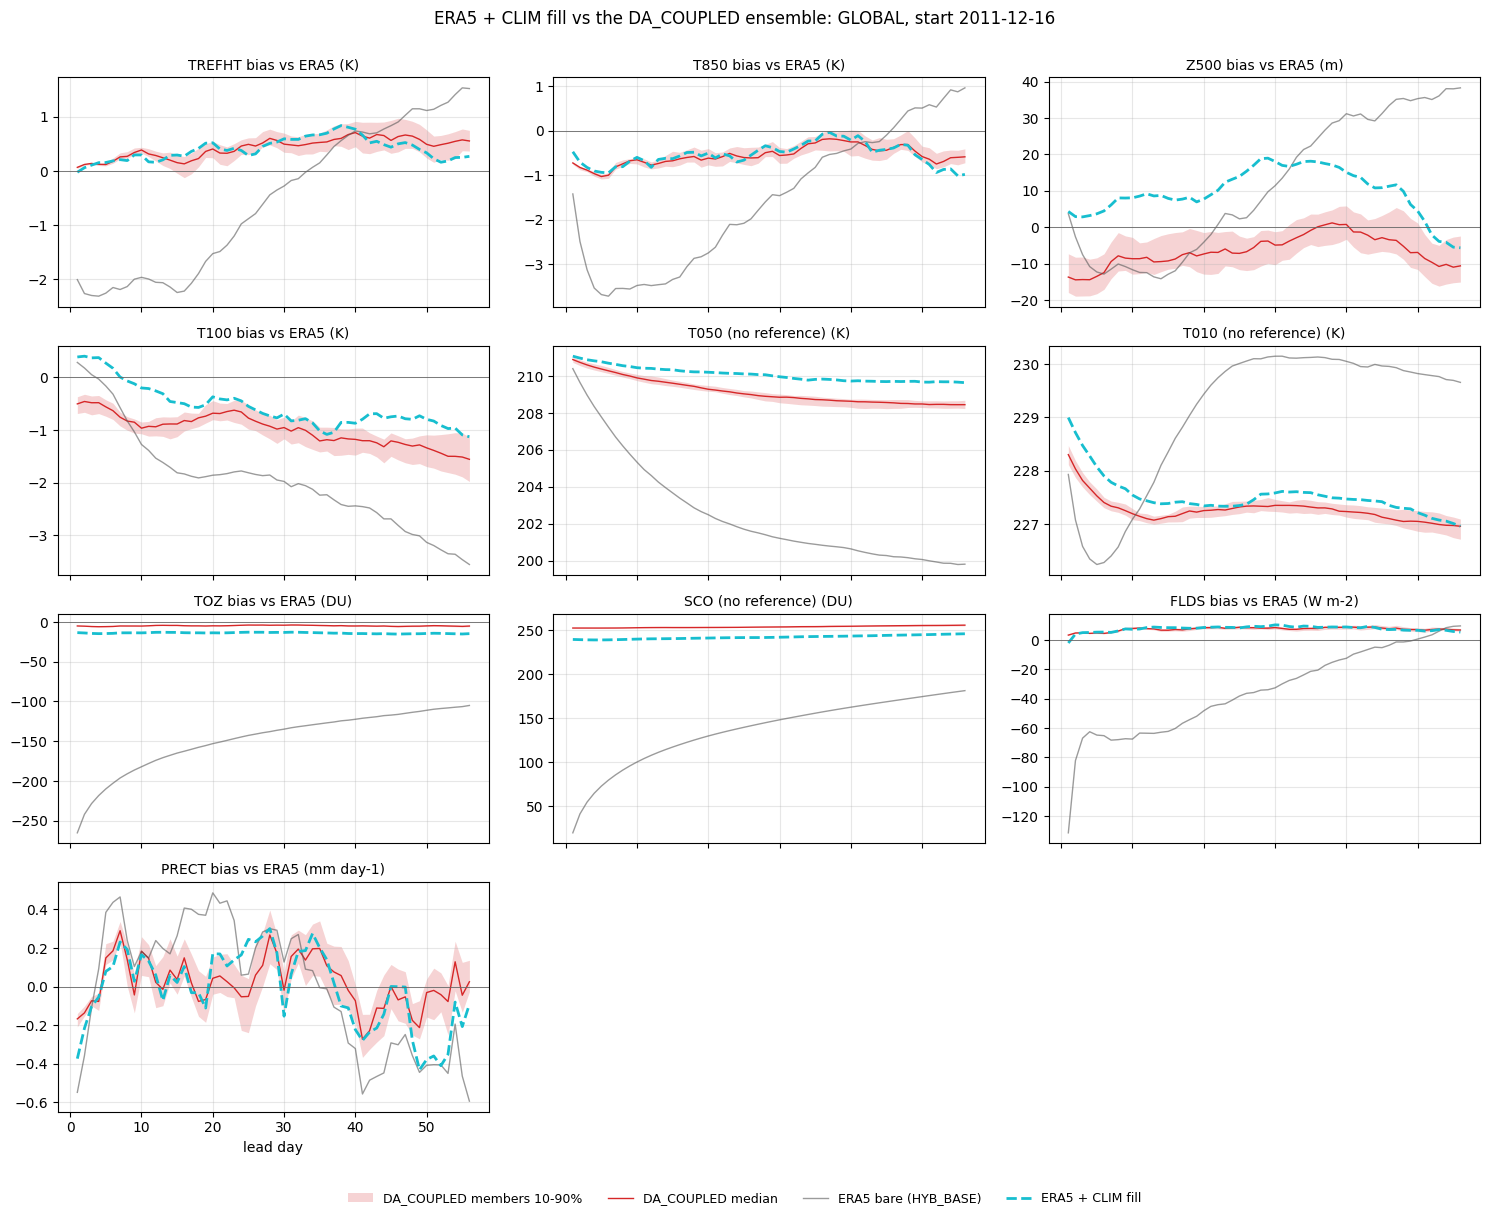

In [8]:
def plot_member_vs_ensemble(c, region):
    run, ens_run, q = ENSEMBLE_COMPARISONS[c]
    vs = [v for v in PLOT_ENSEMBLE_VARIABLES if (ens_run, v) in ensembles]
    ncol = 3
    nrow = int(np.ceil(len(vs) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(5.0 * ncol, 2.9 * nrow), sharex=True, squeeze=False)
    for ax, v in zip(axes.flat, vs):
        ds, e = regional[v], ensembles[ens_run, v]
        key = "bias" if "bias" in ds else "value"
        m = e[f"ens_{key}"].sel(region=region)
        ax.fill_between(m.lead, m.quantile(0.1, "member"), m.quantile(0.9, "member"), color=RUNS[ens_run].color,
                        alpha=0.2, lw=0, label=f"{ens_run} members 10-90%")
        ax.plot(m.lead, m.median("member"), color=RUNS[ens_run].color, lw=1.0, label=f"{ens_run} median")
        for k in RUN_KEYS:
            r = RUNS[k]
            ax.plot(ds.lead, ds[key].sel(run=k, region=region), color=r.color, ls=r.linestyle,
                    lw=2.0 if k == run else 1.0, alpha=1.0 if k == run else 0.6, label=r.label)
        if key == "bias":
            ax.axhline(0, color="0.4", lw=0.6)
        ax.set_title(f"{v} {'bias vs ERA5' if key == 'bias' else '(no reference)'} ({ds.attrs['units']})", fontsize=10)
        ax.grid(alpha=0.3)
    for ax in axes[-1]:
        ax.set_xlabel("lead day")
    for ax in list(axes.flat)[len(vs):]:
        ax.axis("off")
    h, l = axes.flat[0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=4, fontsize=9, frameon=False, bbox_to_anchor=(0.5, -0.04))
    fig.suptitle(f"{RUNS[run].label} vs the {ens_run} ensemble: {region}, start {INIT}", y=1.0)
    fig.tight_layout()
    save(fig, f"ensemble_{c}_{region}.png")
    plt.show()


for c in ENSEMBLE_COMPARISON_KEYS:
    for r in PLOT_REGIONS:
        plot_member_vs_ensemble(c, r)